# DRL Assignment I - Group 6: Bandit experiments

**Paper:** Elise Wolf (2025), [A Framework for Fair Evaluation of Variance-Aware Bandit Algorithms](https://arxiv.org/abs/2510.27001).

| Contributor | BITS ID |
|---|---|
| Ashok Kumar K S | 2025AG05302 |
| Nithyasree A | 2025AG05607 |
| Nallajala Saibhargav | 2025AG05608 |
| Arjun Balaji | 2025AG05609 |

This notebook contains the complete local workflow: simulation, **26 verification checks**, full or quick execution, result tables and plots. It requires no separate Python scripts.

**Run:** install `requirements.txt`, open this notebook from the repository directory, then **Restart Kernel and Run All**. The saved outputs below are from a full run. `RUN_MODE = "quick"` writes separately to `results_quick/`; use `"full"` for the assignment comparisons.

We partially reproduce ETC, UCB and UCB-Tuned, plus an ETC-greedy diagnostic of the paper-linked implementation. The paper evaluates eight existing methods. VaR and reward-variance p-values are outside this reproduction.

## 1. Environment and run settings

Full mode: $T=1,000,000$, 100 trials per algorithm; strict ETC estimates use 100,000 trials and selected ETC-greedy estimates use 1,000. Each task creates its own random generator from `[42, scenario_index, algorithm_code, m]`, so worker scheduling cannot change its stream. Arm order is independently randomized per trial.

In [1]:
from pathlib import Path
from types import SimpleNamespace
from datetime import datetime, timezone
import csv
import hashlib
import inspect
import json
import math
import os
import platform
import random
import time

import numpy as np
import joblib
from joblib import Parallel, delayed
from IPython.display import HTML, Image, display
from html import escape

# Use "quick" only for a shorter smoke run; keep "full" for the presentation results.
RUN_MODE = "full"
WORKERS = min(8, os.cpu_count() or 1)
ROOT = Path.cwd()
if not (ROOT / "DRL_Assignment1_Group6.ipynb").is_file():
    raise FileNotFoundError("Open this notebook from its repository directory.")

SCENARIOS = {"A": (0.80, 0.90), "B": (0.895, 0.90), "C": (0.89, 0.895)}
ETC_M = (10, 100, 1_000, 10_000, 100_000)
SEED = 42
IMPLEMENTATION_VERSION = "group6-1.1"
ALGORITHM_CODES = {"etc": 0, "etc_exp": 1, "greedy": 2, "greedy_exp": 3, "ucb": 4, "ucb_tuned": 5}
GREEDY_EXPECTATION = {("A", 100), ("B", 10_000), ("C", 10_000)}

# Published means and suboptimal-pull ratios, paper Tables 3-5.
PAPER = {
    ("A", "ETC(m=100)"): (10.10, 0.00010),
    ("A", "ETC(m=1000)"): (100.00, 0.00100),
    ("A", "ETC(m=10000)"): (1000.00, 0.01000),
    ("A", "UCB"): (238.17, 0.00238),
    ("A", "UCB-Tuned"): (30.67, 0.00031),
    ("B", "ETC(m=10000)"): (150.66, 0.03013),
    ("B", "UCB"): (1127.17, 0.22543),
    ("B", "UCB-Tuned"): (212.21, 0.04242),
    ("C", "ETC(m=10)"): (2150.00, 0.43000),
    ("C", "ETC(m=10000)"): (170.53, 0.03411),
    ("C", "ETC(m=100000)"): (500.00, 0.10000),
    ("C", "UCB"): (1172.57, 0.23451),
    ("C", "UCB-Tuned"): (226.09, 0.04522),
}

print(f"Mode: {RUN_MODE}; seed: {SEED}; workers: {WORKERS}")
print(f"Python {platform.python_version()}; NumPy {np.__version__}; joblib {joblib.__version__}")

Mode: full; seed: 42; workers: 8
Python 3.14.5; NumPy 2.4.6; joblib 1.6.0


## 2. Simulation core

The measured quantity is cumulative pseudo-regret, $R_t=\sum_{k=1}^t(\mu^*-\mu_{A_k})$. ETC commits after exploring; ETC-greedy continues to update and select empirical means. UCB and UCB-Tuned use the paper's index definitions. The notebook-local `sim` namespace groups these functions without importing a separate module.

In [2]:
"""
Simulation core for two-armed Bernoulli bandits.

Algorithms (definitions from Wolf, 2025, Section 2):
  ETC        explore each arm m times, then commit to the arm with the larger
             empirical mean for the remaining steps (decision fixed after step 2m).
  ETC-greedy explore each arm m times, then at every step play the arm with the
             larger empirical mean; the estimates keep updating, so the played
             arm can change after step 2m. This is how the ETC code of Bandit
             Playground (the paper's framework) behaves.
  UCB        play the arm maximising  Q_hat_a + sqrt(2 ln t / T_a).
  UCB-Tuned  play the arm maximising  Q_hat_a + sqrt( (ln t / T_a) * min(1/4, V_a) ),
             with V_a = (mean of squared rewards) - Q_hat_a^2 + sqrt(2 ln t / T_a)
             (Auer, Cesa-Bianchi and Fischer, 2002).

All trials of one algorithm are simulated together as NumPy arrays of shape
(n_trials, 2). Each trial has its own random assignment of the better arm to
index 0 or 1, so tie-breaking by arm index favours neither arm.

The recorded quantity is cumulative pseudo-regret
  R_t = sum_{k<=t} (Q* - Q_{A_k}),
where Q* is the largest arm mean and A_k is the arm played at step k.
"""
import numpy as np

BLOCK = 2048  # number of time steps for which random numbers are drawn at once


def checkpoints(horizon, per_decade=12):
    """Log-spaced time steps 1 ... horizon at which regret is recorded."""
    n_points = int(per_decade * np.log10(horizon)) + 1
    pts = np.unique(np.round(np.logspace(0, np.log10(horizon), n_points)).astype(np.int64))
    return pts[(pts >= 1) & (pts <= horizon)]


def trial_arm_means(p, n_trials, rng):
    """Arm means per trial, shape (n_trials, 2), with the arm order shuffled per trial."""
    means = np.tile(np.asarray(p, dtype=float), (n_trials, 1))
    swap = rng.random(n_trials) < 0.5
    means[swap] = means[swap][:, ::-1]
    return means


def simulate_etc(means, m, horizon, marks, rng):
    """
    Explore-then-commit with m pulls of each arm.

    Exploration alternates between the arms, so the successes of arm a are
    Binomial(m, p_a) and the commit decision depends only on those counts.
    Returns (regret at each mark, shape (len(marks), n_trials); share of
    suboptimal pulls per trial; boolean array of trials that committed to the
    worse arm).
    """
    n = means.shape[0]
    rows = np.arange(n)
    gap = means.max(axis=1)[:, None] - means          # per-pull regret of each arm
    successes = rng.binomial(m, means)                # exploration outcome, (n, 2)
    commit = (successes[:, 1] > successes[:, 0]).astype(np.intp)
    ties = successes[:, 0] == successes[:, 1]
    commit[ties] = rng.integers(0, 2, ties.sum())     # equal means: pick an arm at random
    committed_gap = gap[rows, commit]

    regret = np.empty((len(marks), n))
    for i, t in enumerate(marks):
        if t <= 2 * m:                                # still exploring: arm 0, arm 1, arm 0, ...
            regret[i] = ((t + 1) // 2) * gap[:, 0] + (t // 2) * gap[:, 1]
        else:
            regret[i] = m * (gap[:, 0] + gap[:, 1]) + (t - 2 * m) * committed_gap
    explore_pulls = min(2 * m, horizon)
    subopt_pulls = ((explore_pulls + 1) // 2) * (gap[:, 0] > 0) + (explore_pulls // 2) * (gap[:, 1] > 0)
    subopt_pulls = subopt_pulls + max(horizon - 2 * m, 0) * (committed_gap > 0)
    return regret, subopt_pulls / horizon, (committed_gap > 0) & (horizon > 2 * m)


def simulate_ucb(means, horizon, marks, rng, tuned=False):
    """
    UCB (tuned=False) or UCB-Tuned (tuned=True), all trials in parallel.

    Each arm is played once first; from round 3 on the arm with the larger
    index is played (ties go to arm 0). Returns (regret at each mark, share of
    suboptimal pulls per trial).
    """
    n = means.shape[0]
    rows = np.arange(n)
    gap = means.max(axis=1)[:, None] - means
    log_n = np.log(np.arange(1, horizon + 1))         # log_n[t] = ln(round t + 1)

    counts = np.ones((n, 2))
    sums = np.zeros((n, 2))
    sumsq = np.zeros((n, 2))
    for arm in (0, 1):
        reward = (rng.random(n) < means[:, arm]).astype(float)
        sums[:, arm] = reward
        sumsq[:, arm] = reward
    regret = gap.sum(axis=1)
    pulls_suboptimal = (gap > 0).astype(float).sum(axis=1)

    mark_slot = {int(t): i for i, t in enumerate(marks)}
    out = np.empty((len(marks), n))
    for t in (1, 2):
        if t in mark_slot:
            out[mark_slot[t]] = gap[:, :t].sum(axis=1)

    t = 2
    while t < horizon:
        stop = min(t + BLOCK, horizon)
        uniforms = rng.random((stop - t, n))
        for j in range(stop - t):
            ln_t = log_n[t]
            mean = sums / counts
            if tuned:
                v = sumsq / counts - mean * mean + np.sqrt(2.0 * ln_t / counts)
                index = mean + np.sqrt(ln_t / counts * np.minimum(0.25, v))
            else:
                index = mean + np.sqrt(2.0 * ln_t / counts)
            arm = (index[:, 1] > index[:, 0]).astype(np.intp)
            reward = (uniforms[j] < means[rows, arm]).astype(float)
            counts[rows, arm] += 1.0
            sums[rows, arm] += reward
            sumsq[rows, arm] += reward
            step_gap = gap[rows, arm]
            regret = regret + step_gap
            pulls_suboptimal = pulls_suboptimal + (step_gap > 0)
            t += 1
            slot = mark_slot.get(t)
            if slot is not None:
                out[slot] = regret
    return out, pulls_suboptimal / horizon


def simulate_etc_greedy(means, m, horizon, marks, rng):
    """
    Explore m pulls of each arm (alternating), then play the arm with the larger
    running empirical mean at every step; estimates keep updating.

    Returns (regret at each mark, share of suboptimal pulls per trial,
    boolean array of trials whose final regret exceeds the exploration cost
    by more than 100 * gap, i.e. trials that spent a long period on the worse arm).
    """
    n = means.shape[0]
    rows = np.arange(n)
    gap = means.max(axis=1)[:, None] - means
    if horizon < 2 * m:
        # The horizon ends during alternating exploration: no exploitation occurs.
        # Avoid preloading rewards/counts for pulls beyond the requested horizon.
        out = np.empty((len(marks), n))
        for i, t in enumerate(marks):
            out[i] = ((t + 1) // 2) * gap[:, 0] + (t // 2) * gap[:, 1]
        pulls_suboptimal = ((horizon + 1) // 2) * (gap[:, 0] > 0) + (horizon // 2) * (gap[:, 1] > 0)
        return out, pulls_suboptimal / horizon, np.zeros(n, dtype=bool)
    counts = np.full((n, 2), float(m))
    sums = rng.binomial(m, means).astype(float)       # exploration outcome, (n, 2)
    explore_regret = m * gap.sum(axis=1)
    regret = explore_regret.copy()
    pulls_suboptimal = np.full(n, float(m)) * ((gap[:, 0] > 0).astype(float) + (gap[:, 1] > 0))

    mark_slot = {int(t): i for i, t in enumerate(marks)}
    out = np.empty((len(marks), n))
    for i, t in enumerate(marks):
        if t <= 2 * m:                                # exploration: arm 0, arm 1, arm 0, ...
            out[i] = ((t + 1) // 2) * gap[:, 0] + (t // 2) * gap[:, 1]

    t = 2 * m
    while t < horizon:
        stop = min(t + BLOCK, horizon)
        uniforms = rng.random((stop - t, n))
        for j in range(stop - t):
            mean = sums / counts
            arm = (mean[:, 1] > mean[:, 0]).astype(np.intp)
            reward = (uniforms[j] < means[rows, arm]).astype(float)
            counts[rows, arm] += 1.0
            sums[rows, arm] += reward
            step_gap = gap[rows, arm]
            regret = regret + step_gap
            pulls_suboptimal = pulls_suboptimal + (step_gap > 0)
            t += 1
            slot = mark_slot.get(t)
            if slot is not None:
                out[slot] = regret
    long_on_worse_arm = (regret - explore_regret) > 100 * gap.max(axis=1)
    return out, pulls_suboptimal / horizon, long_on_worse_arm

# Notebook-local namespace: no external Python modules are required.
sim = SimpleNamespace(
    checkpoints=checkpoints,
    trial_arm_means=trial_arm_means,
    simulate_etc=simulate_etc,
    simulate_ucb=simulate_ucb,
    simulate_etc_greedy=simulate_etc_greedy,
)

## 3. Verification (26 checks)

These retained checks compare ETC against a normal approximation, UCB/UCB-Tuned and ETC-greedy against independently written plain loops, and regret bookkeeping against bounds and exploration cutoffs. The normal approximation includes an allowance for approximation error. Independent reference RNG streams test statistical agreement, not identical paths. A failure raises an exception and stops Run All.

In [3]:
def run_verification():
    """Run the 26 existing scientific and boundary checks; stop on failure."""
    SCENARIOS = {"A": (0.80, 0.90), "B": (0.895, 0.90), "C": (0.89, 0.895)}
    results = []


    def report(name, ok, detail):
        results.append(ok)
        print(f"[{'PASS' if ok else 'FAIL'}] {name}: {detail}")


    # ---------------------------------------------------------------- 1. ETC lock-in
    def norm_cdf(x):
        return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))


    def etc_wrong_probability(p, m):
        gap = abs(p[1] - p[0])
        sd = math.sqrt((p[0] * (1 - p[0]) + p[1] * (1 - p[1])) / m)
        return norm_cdf(-gap / sd)


    rng = np.random.default_rng(11)
    for scen, m in (("A", 100), ("B", 10_000), ("C", 10_000), ("C", 100_000)):
        p = SCENARIOS[scen]
        n = 200_000
        means = sim.trial_arm_means(p, n, rng)
        _, _, wrong = sim.simulate_etc(means, m, 4 * m, np.array([4 * m]), rng)
        observed = wrong.mean()
        expected = etc_wrong_probability(p, m)
        tol = 4 * math.sqrt(expected * (1 - expected) / n) + 0.01  # sampling error + normal-approx error
        report(f"ETC wrong-commit rate, scenario {scen}, m={m}",
               abs(observed - expected) <= tol, f"simulated {observed:.4f}, normal approximation {expected:.4f}")


    # ----------------------------------------------- 2. UCB / UCB-Tuned vs plain loops
    def reference_run(p, horizon, tuned, seed):
        """One trial of UCB / UCB-Tuned written with plain Python lists, no vectorisation."""
        r = random.Random(seed)
        best = max(p)
        n_pulls = [0, 0]
        total = [0.0, 0.0]
        total_sq = [0.0, 0.0]
        regret = 0.0
        for t in range(1, horizon + 1):
            if t <= 2:
                arm = t - 1
            else:
                index = []
                for a in (0, 1):
                    mean = total[a] / n_pulls[a]
                    if tuned:
                        v = total_sq[a] / n_pulls[a] - mean ** 2 + math.sqrt(2 * math.log(t) / n_pulls[a])
                        bonus = math.sqrt(math.log(t) / n_pulls[a] * min(0.25, v))
                    else:
                        bonus = math.sqrt(2 * math.log(t) / n_pulls[a])
                    index.append(mean + bonus)
                arm = 1 if index[1] > index[0] else 0
            x = 1.0 if r.random() < p[arm] else 0.0
            n_pulls[arm] += 1
            total[arm] += x
            total_sq[arm] += x * x
            regret += best - p[arm]
        return regret


    horizon, trials = 5_000, 300
    for scen in ("A", "C"):
        p = SCENARIOS[scen]
        for tuned in (False, True):
            ref = np.array([reference_run(p, horizon, tuned, s) for s in range(trials)])
            means = sim.trial_arm_means(p, trials, np.random.default_rng(5))
            out, _ = sim.simulate_ucb(means, horizon, np.array([horizon]), np.random.default_rng(6), tuned=tuned)
            vec = out[0]
            se = math.sqrt(ref.var(ddof=1) / trials + vec.var(ddof=1) / trials)
            diff = abs(ref.mean() - vec.mean())
            report(f"{'UCB-Tuned' if tuned else 'UCB'} vs plain-loop reference, scenario {scen}, T={horizon}",
                   diff <= 3.5 * se,
                   f"reference {ref.mean():.2f}, simulation {vec.mean():.2f}, difference {diff:.2f} (3.5 s.e. = {3.5 * se:.2f})")

    def reference_etc_greedy(p, m, horizon, seed):
        """One trial of ETC-greedy with plain Python lists: m pulls per arm, then greedy on running means."""
        r = random.Random(seed)
        best = max(p)
        n_pulls = [0, 0]
        total = [0.0, 0.0]
        regret = 0.0
        for t in range(1, horizon + 1):
            if t <= 2 * m:
                arm = (t - 1) % 2
            else:
                means = [total[a] / n_pulls[a] for a in (0, 1)]
                arm = 1 if means[1] > means[0] else 0
            x = 1.0 if r.random() < p[arm] else 0.0
            n_pulls[arm] += 1
            total[arm] += x
            regret += best - p[arm]
        return regret


    horizon, trials, m = 4_000, 400, 100
    for scen in ("A", "C"):
        p = SCENARIOS[scen]
        ref = np.array([reference_etc_greedy(p, m, horizon, s) for s in range(trials)])
        means = sim.trial_arm_means(p, trials, np.random.default_rng(8))
        out, _, _ = sim.simulate_etc_greedy(means, m, horizon, np.array([horizon]), np.random.default_rng(9))
        vec = out[0]
        se = math.sqrt(ref.var(ddof=1) / trials + vec.var(ddof=1) / trials)
        diff = abs(ref.mean() - vec.mean())
        report(f"ETC-greedy vs plain-loop reference, scenario {scen}, m={m}, T={horizon}",
               diff <= 3.5 * se,
               f"reference {ref.mean():.2f}, simulation {vec.mean():.2f}, difference {diff:.2f} (3.5 s.e. = {3.5 * se:.2f})")

    # ------------------------------------------------------ 3. regret bookkeeping
    marks = sim.checkpoints(20_000)
    means = sim.trial_arm_means(SCENARIOS["A"], 50, np.random.default_rng(3))
    for name, (out, *_rest) in {
        "UCB": sim.simulate_ucb(means, 20_000, marks, np.random.default_rng(4), tuned=False),
        "UCB-Tuned": sim.simulate_ucb(means, 20_000, marks, np.random.default_rng(4), tuned=True),
        "ETC m=100": sim.simulate_etc(means, 100, 20_000, marks, np.random.default_rng(4)),
        "ETC-greedy m=100": sim.simulate_etc_greedy(means, 100, 20_000, marks, np.random.default_rng(4)),
    }.items():
        monotone = bool(np.all(np.diff(out, axis=0) >= -1e-9))
        bounded = bool(np.all(out <= 0.1 * marks[:, None] + 1e-9))
        report(f"regret bookkeeping, {name}", monotone and bounded, "non-decreasing in t and at most gap * t")

    # ----------------------------------------- 4. exploration cutoffs and odd horizons
    # Both arm orders make an omitted final arm-0 pull observable. These expectations
    # follow directly from one alternating action per round, independent of rewards.
    boundary_means = np.array([[0.80, 0.90], [0.90, 0.80]])
    boundary_gap = boundary_means.max(axis=1)[:, None] - boundary_means
    for name, simulate in (("ETC", sim.simulate_etc), ("ETC-greedy", sim.simulate_etc_greedy)):
        for horizon in (3, 4, 5, 6, 7):
            m = 3
            boundary_marks = np.arange(1, horizon + 1)
            out, ratio, flagged = simulate(boundary_means, m, horizon, boundary_marks, np.random.default_rng(12))
            implied_regret = boundary_gap.max(axis=1) * horizon * ratio
            ratio_matches = bool(np.allclose(out[-1], implied_regret, atol=1e-12, rtol=0))
            exploration_marks = boundary_marks[boundary_marks <= 2 * m]
            expected_exploration = (((exploration_marks + 1) // 2)[:, None] * boundary_gap[:, 0]
                                    + (exploration_marks // 2)[:, None] * boundary_gap[:, 1])
            exploration_matches = bool(np.allclose(out[:len(exploration_marks)], expected_exploration,
                                                  atol=1e-12, rtol=0))
            no_commit_before_exploitation = horizon > 2 * m or not bool(np.any(flagged))
            report(f"exploration cutoff, {name}, m={m}, T={horizon}",
                   ratio_matches and exploration_matches and no_commit_before_exploitation,
                   "alternating pulls through cutoff; regret = gap * T * suboptimal ratio")

    # The documented quick mode has m=100,000 at T=100,000: exactly half the pulls
    # are suboptimal, with no post-exploration action and regret 250 for gap 0.005.
    quick_means = np.array([[0.89, 0.895], [0.895, 0.89]])
    for name, simulate in (("ETC", sim.simulate_etc), ("ETC-greedy", sim.simulate_etc_greedy)):
        out, ratio, flagged = simulate(quick_means, 100_000, 100_000, np.array([100_000]),
                                      np.random.default_rng(13))
        ok = bool(np.allclose(out[-1], 250.0) and np.allclose(ratio, 0.5) and not np.any(flagged))
        report(f"quick-mode exploration cutoff, {name}", ok, "regret 250; suboptimal ratio 0.5; no commitment")

    print()
    print("ALL CHECKS PASSED" if all(results) else "SOME CHECKS FAILED")
    if len(results) != 26 or not all(results):
        raise AssertionError(f"Verification failed: {sum(results)}/{len(results)} checks passed.")
    return {"checks": len(results), "passed": int(sum(results)), "all_passed": all(results)}

In [4]:
verification = run_verification()
print(f"Verification: {verification['passed']}/{verification['checks']} passed")

[PASS] ETC wrong-commit rate, scenario A, m=100: simulated 0.0229, normal approximation 0.0228


[PASS] ETC wrong-commit rate, scenario B, m=10000: simulated 0.1212, normal approximation 0.1219
[PASS] ETC wrong-commit rate, scenario C, m=10000: simulated 0.1274, normal approximation 0.1268
[PASS] ETC wrong-commit rate, scenario C, m=100000: simulated 0.0001, normal approximation 0.0002


[PASS] UCB vs plain-loop reference, scenario A, T=5000: reference 63.96, simulation 65.13, difference 1.17 (3.5 s.e. = 3.44)


[PASS] UCB-Tuned vs plain-loop reference, scenario A, T=5000: reference 16.12, simulation 16.09, difference 0.02 (3.5 s.e. = 5.29)


[PASS] UCB vs plain-loop reference, scenario C, T=5000: reference 11.82, simulation 11.80, difference 0.02 (3.5 s.e. = 0.37)


[PASS] UCB-Tuned vs plain-loop reference, scenario C, T=5000: reference 10.73, simulation 11.13, difference 0.40 (3.5 s.e. = 1.01)


[PASS] ETC-greedy vs plain-loop reference, scenario A, m=100, T=4000: reference 12.51, simulation 10.10, difference 2.41 (3.5 s.e. = 4.77)


[PASS] ETC-greedy vs plain-loop reference, scenario C, m=100, T=4000: reference 9.52, simulation 8.76, difference 0.76 (3.5 s.e. = 2.24)


[PASS] regret bookkeeping, UCB: non-decreasing in t and at most gap * t
[PASS] regret bookkeeping, UCB-Tuned: non-decreasing in t and at most gap * t
[PASS] regret bookkeeping, ETC m=100: non-decreasing in t and at most gap * t
[PASS] regret bookkeeping, ETC-greedy m=100: non-decreasing in t and at most gap * t
[PASS] exploration cutoff, ETC, m=3, T=3: alternating pulls through cutoff; regret = gap * T * suboptimal ratio
[PASS] exploration cutoff, ETC, m=3, T=4: alternating pulls through cutoff; regret = gap * T * suboptimal ratio
[PASS] exploration cutoff, ETC, m=3, T=5: alternating pulls through cutoff; regret = gap * T * suboptimal ratio
[PASS] exploration cutoff, ETC, m=3, T=6: alternating pulls through cutoff; regret = gap * T * suboptimal ratio
[PASS] exploration cutoff, ETC, m=3, T=7: alternating pulls through cutoff; regret = gap * T * suboptimal ratio
[PASS] exploration cutoff, ETC-greedy, m=3, T=3: alternating pulls through cutoff; regret = gap * T * suboptimal ratio
[PASS] e

## 4. Experiment runner

Tasks preserve the previous scenario order, random calls, checkpoints, rounding and paper entries. `joblib` uses its `loky` process backend so notebook-defined functions can run on Windows. Runtime source fingerprints cover the executed simulation, runner and verification functions and their constants; outputs and execution counts are excluded. This also records edits executed before saving the notebook.

In [5]:
def describe(final_regret, subopt_ratio):
    n = len(final_regret)
    return {
        "mean": float(final_regret.mean()),
        "std": float(final_regret.std(ddof=1)),
        "sem": float(final_regret.std(ddof=1) / np.sqrt(n)),
        "median": float(np.median(final_regret)),
        "subopt_ratio": float(np.mean(subopt_ratio)),
    }


def run_task(task):
    """One (scenario, algorithm) simulation. Seeds depend only on the task, not on execution order."""
    kind, scen, m, horizon, trials, expectation_trials = task
    p = SCENARIOS[scen]
    s_idx = list(SCENARIOS).index(scen)
    code = ALGORITHM_CODES[kind]
    rng = np.random.default_rng([SEED, s_idx, code, m])
    marks = sim.checkpoints(horizon)
    result = {"kind": kind, "scenario": scen, "m": m}

    if kind == "etc":
        means = sim.trial_arm_means(p, trials, rng)
        regret, subopt, flag = sim.simulate_etc(means, m, horizon, marks, rng)
    elif kind == "greedy":
        means = sim.trial_arm_means(p, trials, rng)
        regret, subopt, flag = sim.simulate_etc_greedy(means, m, horizon, marks, rng)
    elif kind == "etc_exp":
        means = sim.trial_arm_means(p, expectation_trials, rng)
        regret, subopt, flag = sim.simulate_etc(means, m, horizon, marks[-1:], rng)
        result.update(trials=expectation_trials, expected_regret=float(regret[-1].mean()),
                      sem=float(regret[-1].std(ddof=1) / np.sqrt(expectation_trials)),
                      flagged_rate=float(flag.mean()))
        return result
    elif kind == "greedy_exp":
        means = sim.trial_arm_means(p, expectation_trials, rng)
        regret, subopt, flag = sim.simulate_etc_greedy(means, m, horizon, marks[-1:], rng)
        result.update(trials=expectation_trials, expected_regret=float(regret[-1].mean()),
                      sem=float(regret[-1].std(ddof=1) / np.sqrt(expectation_trials)),
                      flagged_rate=float(flag.mean()))
        return result
    else:
        means = sim.trial_arm_means(p, trials, rng)
        regret, subopt = sim.simulate_ucb(means, horizon, marks, rng, tuned=(kind == "ucb_tuned"))
        flag = None

    result.update(curve=regret.mean(axis=1).tolist(), flagged=None if flag is None else int(flag.sum()),
                  **describe(regret[-1], subopt))
    return result


def algorithm_name(kind, m):
    return {"etc": f"ETC(m={m})", "greedy": f"ETC-greedy(m={m})", "ucb": "UCB", "ucb_tuned": "UCB-Tuned"}[kind]


def write_csv(path, header, rows):
    with open(path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(header)
        for r in rows:
            w.writerow([round(v, 5) if isinstance(v, float) else v for v in r])


def implementation_hashes():
    """Fingerprint executed function sources and constants, including unsaved cell edits."""
    def digest(functions, constants):
        payload = {
            "functions": {f.__name__: inspect.getsource(f) for f in functions},
            "constants": constants,
        }
        encoded = json.dumps(payload, sort_keys=True, separators=(",", ":")).encode("utf-8")
        return hashlib.sha256(encoded).hexdigest()
    return {
        "simulation_core": digest(
            [checkpoints, trial_arm_means, simulate_etc, simulate_ucb, simulate_etc_greedy],
            {"BLOCK": BLOCK}),
        "experiment_runner": digest(
            [describe, run_task, algorithm_name, write_csv, run_experiment],
            {"SCENARIOS": SCENARIOS, "scenario_order": list(SCENARIOS), "ETC_M": ETC_M, "SEED": SEED,
             "ALGORITHM_CODES": ALGORITHM_CODES,
             "GREEDY_EXPECTATION": sorted(GREEDY_EXPECTATION),
             "PAPER": [[list(k), list(v)] for k, v in PAPER.items()]}),
        "verification": digest([run_verification], {}),
    }



def run_experiment(mode="full", workers=WORKERS, output_dir=None):
    """Run the fixed-seed experiment and export tables plus aggregate regret curves."""
    if mode not in {"full", "quick"}:
        raise ValueError('mode must be "full" or "quick".')
    if not isinstance(workers, int) or workers < 1:
        raise ValueError("workers must be a positive integer.")
    if not verification["all_passed"] or verification["checks"] != 26:
        raise RuntimeError("Run and pass the Verification section first.")
    default_folder = "results_quick" if mode == "quick" else "results"
    args = SimpleNamespace(quick=(mode == "quick"), workers=workers,
                           out=str(ROOT / default_folder) if output_dir is None else str(output_dir))
    horizon, trials = (100_000, 20) if args.quick else (1_000_000, 100)
    strict_exp, greedy_exp = (5_000, 100) if args.quick else (100_000, 1_000)
    os.makedirs(args.out, exist_ok=True)

    tasks = []
    for scen in SCENARIOS:
        for m in ETC_M:
            tasks.append(("greedy", scen, m, horizon, trials, 0))
            tasks.append(("etc", scen, m, horizon, trials, 0))
            tasks.append(("etc_exp", scen, m, horizon, 0, strict_exp))
            if (scen, m) in GREEDY_EXPECTATION:
                tasks.append(("greedy_exp", scen, m, horizon, 0, greedy_exp))
        tasks.append(("ucb", scen, 0, horizon, trials, 0))
        tasks.append(("ucb_tuned", scen, 0, horizon, trials, 0))
    # long tasks first, so the worker pool stays busy to the end
    tasks.sort(key=lambda t: {"greedy_exp": 0, "greedy": 1, "ucb_tuned": 2, "ucb": 3}.get(t[0], 4))

    started = time.time()
    results = []
    completed = Parallel(n_jobs=args.workers, backend="loky", return_as="generator")(
        delayed(run_task)(task) for task in tasks)
    for res in completed:
        results.append(res)
        label = algorithm_name(res["kind"], res["m"]) if "curve" in res else f"{res['kind']} m={res['m']}"
        print(f"[{time.time() - started:5.0f}s] scenario {res['scenario']}  {label}", flush=True)

    # ---- tables
    summary, curves, expected = [], {s: {} for s in SCENARIOS}, []
    for res in results:
        if "curve" in res:
            name = algorithm_name(res["kind"], res["m"])
            curves[res["scenario"]][name] = res["curve"]
            summary.append((res["scenario"], name, horizon, trials, res["mean"], res["std"], res["sem"],
                            res["median"], res["subopt_ratio"], "" if res["flagged"] is None else res["flagged"]))
        else:
            expected.append((res["scenario"], "ETC" if res["kind"] == "etc_exp" else "ETC-greedy", res["m"],
                             horizon, res["trials"], res["expected_regret"], res["sem"], res["flagged_rate"]))
    order = {"A": 0, "B": 1, "C": 2}
    algo_order = lambda n: (0 if n.startswith("ETC(") else 1 if n.startswith("ETC-g") else 2 if n == "UCB" else 3)
    summary.sort(key=lambda r: (order[r[0]], algo_order(r[1]), int(r[1].split("=")[1].rstrip(")")) if "=" in r[1] else 0))
    expected.sort(key=lambda r: (order[r[0]], r[1], r[2]))

    write_csv(os.path.join(args.out, "summary.csv"),
              ["scenario", "algorithm", "horizon", "trials", "mean", "std", "sem", "median", "subopt_ratio",
               "trials_on_worse_arm"], summary)
    write_csv(os.path.join(args.out, "etc_expected.csv"),
              ["scenario", "algorithm", "m", "horizon", "trials", "expected_regret", "sem", "worse_arm_rate"],
              expected)

    by_key = {(r[0], r[1]): r for r in summary}
    rows = []
    for (scen, name), (reg, ratio) in PAPER.items():
        variants = [name] if not name.startswith("ETC") else [name, name.replace("ETC(", "ETC-greedy(")]
        for ours in variants:
            r = by_key[(scen, ours)]
            rows.append((scen, name, ours, reg, r[4], r[6], r[4] / reg, ratio, r[8], horizon, trials))
    write_csv(os.path.join(args.out, "comparison.csv"),
              ["scenario", "paper_algorithm", "our_algorithm", "paper_regret", "our_regret", "our_sem",
               "our_over_paper", "paper_subopt_ratio", "our_subopt_ratio", "horizon", "trials"], rows)

    source_hashes = implementation_hashes()
    metadata = {
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "python_version": platform.python_version(),
        "numpy_version": np.__version__,
        "base_seed": SEED,
        "rng_bit_generator": np.random.default_rng().bit_generator.__class__.__name__,
        "task_seed_schema": "[base_seed, scenario_index_in_ABC, algorithm_code, exploration_m]",
        "algorithm_codes": ALGORITHM_CODES,
        "algorithm_implementation_version": IMPLEMENTATION_VERSION,
        "source_sha256": source_hashes,
        "source_artifact": "DRL_Assignment1_Group6.ipynb",
        "source_hash_scheme": "SHA256 of canonical JSON of executed function sources and constants; outputs excluded",
        "execution_workflow_version": "group6-notebook-1.0",
        "joblib_version": joblib.__version__,
        "parallel_backend": "loky",
        "verification_passes": verification["passed"],
        "reproduction_scope": "ETC, ETC-greedy, UCB, UCB-Tuned; partial algorithm/metric reproduction",
        "arm_order_protocol": "independent random swap per trial; not exhaustive permutations",
        "paper_comparison_horizon_matches": horizon == 1_000_000,
        "stored_data_scope": "aggregate mean curves; per-trial trajectories are not retained",
    }
    with open(os.path.join(args.out, "raw_results.json"), "w") as f:
        json.dump({"horizon": horizon, "trials": trials, "scenarios": SCENARIOS,
                   "checkpoints": sim.checkpoints(horizon).tolist(), "mean_regret_curves": curves,
                   "metadata": metadata}, f)

    print(f"\nSaved summary.csv, etc_expected.csv, comparison.csv, raw_results.json to {Path(args.out).name}/"
          f"  ({time.time() - started:.0f}s)")
    return Path(args.out)

## 5. Run the experiment

Full mode regenerates `results/`; quick mode writes `results_quick/` with a shorter horizon and fewer trials. Quick-mode paper columns are retained as reference entries and are not like-for-like full-horizon comparisons. Execute the Verification section first.

In [6]:
OUT = run_experiment(mode=RUN_MODE, workers=WORKERS)

[   42s] scenario A  greedy_exp m=100


[   43s] scenario B  greedy_exp m=10000


[   43s] scenario C  greedy_exp m=10000


[   43s] scenario A  ETC-greedy(m=10)


[   43s] scenario A  ETC-greedy(m=100)


...

[   57s] scenario C  ETC(m=10000)


[   57s] scenario C  etc_exp m=10000


[   57s] scenario C  ETC(m=100000)


[   57s] scenario C  etc_exp m=100000



Saved summary.csv, etc_expected.csv, comparison.csv, raw_results.json to results/  (57s)


## 6. Tables and paper comparisons

The CSVs are the canonical numerical record. `sem` and `our_sem` are **one standard error of the mean**, not confidence intervals. The 100-trial means and larger-trial estimates are different datasets. The latter are Monte Carlo estimates, not exact expectations.

In [7]:
def show_csv(filename, title):
    with open(OUT / filename, newline="", encoding="utf-8") as f:
        rows = list(csv.reader(f))
    header, data = rows[0], rows[1:]
    html = "<h3>" + escape(title) + "</h3><table><thead><tr>"
    html += "".join("<th>" + escape(v) + "</th>" for v in header) + "</tr></thead><tbody>"
    for row in data:
        html += "<tr>" + "".join("<td>" + escape(v) + "</td>" for v in row) + "</tr>"
    display(HTML(html + "</tbody></table>"))
    print(f"{filename}: {len(data)} rows")

show_csv("summary.csv", "All simulated methods and exploration budgets")
show_csv("comparison.csv", "Published means and our simulated means")
show_csv("etc_expected.csv", "Separate larger-trial Monte Carlo estimates")

scenario,algorithm,horizon,trials,mean,std,sem,median,subopt_ratio,trials_on_worse_arm
A,ETC(m=10),1000000,100,25000.5,43518.5436,4351.85436,1.0,0.25001,25
A,ETC(m=100),1000000,100,1009.8,9998.0,999.8,10.0,0.0101,1
A,ETC(m=1000),1000000,100,100.0,0.0,0.0,100.0,0.001,0
A,ETC(m=10000),1000000,100,1000.0,0.0,0.0,1000.0,0.01,0
A,ETC(m=100000),1000000,100,10000.0,0.0,0.0,10000.0,0.1,0
A,ETC-greedy(m=10),1000000,100,12001.951,32658.6972,3265.86972,1.15,0.12002,15
A,ETC-greedy(m=100),1000000,100,10.006,0.06,0.006,10.0,0.0001,0
A,ETC-greedy(m=1000),1000000,100,100.0,0.0,0.0,100.0,0.001,0
A,ETC-greedy(m=10000),1000000,100,1000.0,0.0,0.0,1000.0,0.01,0
A,ETC-greedy(m=100000),1000000,100,10000.0,0.0,0.0,10000.0,0.1,0


summary.csv: 36 rows


scenario,paper_algorithm,our_algorithm,paper_regret,our_regret,our_sem,our_over_paper,paper_subopt_ratio,our_subopt_ratio,horizon,trials
A,ETC(m=100),ETC(m=100),10.1,1009.8,999.8,99.9802,0.0001,0.0101,1000000,100
A,ETC(m=100),ETC-greedy(m=100),10.1,10.006,0.006,0.99069,0.0001,0.0001,1000000,100
A,ETC(m=1000),ETC(m=1000),100.0,100.0,0.0,1.0,0.001,0.001,1000000,100
A,ETC(m=1000),ETC-greedy(m=1000),100.0,100.0,0.0,1.0,0.001,0.001,1000000,100
A,ETC(m=10000),ETC(m=10000),1000.0,1000.0,0.0,1.0,0.01,0.01,1000000,100
A,ETC(m=10000),ETC-greedy(m=10000),1000.0,1000.0,0.0,1.0,0.01,0.01,1000000,100
A,UCB,UCB,238.17,247.041,4.29155,1.03725,0.00238,0.00247,1000000,100
A,UCB-Tuned,UCB-Tuned,30.67,31.084,1.26615,1.0135,0.00031,0.00031,1000000,100
B,ETC(m=10000),ETC(m=10000),150.66,638.0,160.03333,4.2347,0.03013,0.1276,1000000,100
B,ETC(m=10000),ETC-greedy(m=10000),150.66,189.8126,74.33361,1.25987,0.03013,0.03796,1000000,100


comparison.csv: 20 rows


scenario,algorithm,m,horizon,trials,expected_regret,sem,worse_arm_rate
A,ETC,10,1000000,100000,26975.4605,140.34922,0.26975
A,ETC,100,1000000,100000,2184.565,46.11794,0.02175
A,ETC,1000,1000000,100000,100.0,0.0,0.0
A,ETC,10000,1000000,100000,1000.0,0.0,0.0
A,ETC,100000,1000000,100000,10000.0,0.0,0.0
A,ETC-greedy,100,1000000,1000,110.2053,99.97929,0.008
B,ETC,10,1000000,100000,2428.25144,7.90232,0.48565
B,ETC,100,1000000,100000,2258.64828,7.86722,0.45172
B,ETC,1000,1000000,100000,1785.5318,7.55951,0.35682
B,ETC,10000,1000000,100000,654.611,5.09614,0.12339


etc_expected.csv: 18 rows


## 7. Plotting functions

The curve endpoint labels and comparison mean labels use two decimals. Comparison error bars use the stored local `our_sem`; the paper supplies means here. The same published ETC mean is repeated beside the two local ETC variants. Plot-specific exploration settings are kept separate from the five-value experiment sweep.

In [8]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

PALETTE = {
    "background": "#F6F4EF",
    "ink": "#1D2B2F",
    "muted": "#6B7780",
    "grid": "#DDD8CC",
    "ETC": "#1F5C63",
    "ETC-strict": "#0F2F34",
    "UCB": "#8A949B",
    "UCB-Tuned": "#C0613A",
    "paper": "#C9BFA9",
    "ours": "#1F5C63",
}
# ETC exploration length shown per scenario (the paper's best-performing setting)
PLOT_ETC_M = {"A": 100, "B": 10000, "C": 10000}
TITLES = {"A": "Scenario A  (0.80 vs 0.90)",
          "B": "Scenario B  (0.895 vs 0.90)",
          "C": "Scenario C  (0.89 vs 0.895)"}


def style(ax):
    ax.set_facecolor(PALETTE["background"])
    ax.grid(True, color=PALETTE["grid"], linewidth=0.7)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(PALETTE["grid"])
    ax.tick_params(colors=PALETTE["muted"], labelsize=9)


def plot_curves(raw):
    marks = raw["checkpoints"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), facecolor=PALETTE["background"])
    for ax, scen in zip(axes, "ABC"):
        style(ax)
        curves = raw["mean_regret_curves"][scen]
        m = PLOT_ETC_M[scen]
        lines = [
            (f"ETC-greedy(m={m})", f"ETC-greedy m={m}", PALETTE["ETC"], "-"),
            (f"ETC(m={m})", f"ETC strict m={m}", PALETTE["ETC-strict"], "--"),
            ("UCB", "UCB", PALETTE["UCB"], "-"),
            ("UCB-Tuned", "UCB-Tuned", PALETTE["UCB-Tuned"], "-"),
        ]
        for key, label, color, ls in lines:
            ax.plot(marks, curves[key], color=color, linewidth=2.0, linestyle=ls,
                    label=f"{label}  ({curves[key][-1]:,.2f})")
        ax.set_xscale("log")
        ax.set_title(TITLES[scen], fontsize=11, color=PALETTE["ink"], loc="left")
        ax.set_xlabel("time step t (log scale)", fontsize=9, color=PALETTE["muted"])
        if scen == "A":
            ax.set_ylabel("mean cumulative regret", fontsize=9, color=PALETTE["muted"])
        ax.legend(frameon=False, fontsize=8, loc="upper left", labelcolor=PALETTE["ink"])
    fig.text(0.5, 0.025,
             f"T = {raw['horizon']:,}; {raw['trials']:,} trials per algorithm. "
             "Legend values are final mean regrets, rounded to two decimals.",
             ha="center", fontsize=8.5, color=PALETTE["muted"])
    fig.tight_layout(rect=[0, 0.07, 1, 1])
    fig.savefig(os.path.join(RESULTS, "regret_curves.png"), dpi=170, facecolor=PALETTE["background"])
    plt.close(fig)


def plot_vs_paper():
    rows = list(csv.DictReader(open(os.path.join(RESULTS, "comparison.csv"))))
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), facecolor=PALETTE["background"])
    for ax, scen in zip(axes, "ABC"):
        style(ax)
        m = PLOT_ETC_M[scen]
        wanted = [(f"ETC(m={m})", f"ETC-greedy(m={m})", "ETC-greedy"),
                  (f"ETC(m={m})", f"ETC(m={m})", "ETC strict"),
                  ("UCB", "UCB", "UCB"),
                  ("UCB-Tuned", "UCB-Tuned", "UCB-Tuned")]
        for i, (paper_name, our_name, label) in enumerate(wanted):
            r = next(r for r in rows if r["scenario"] == scen and r["paper_algorithm"] == paper_name
                     and r["our_algorithm"] == our_name)
            paper, ours, sem = (float(r[key]) for key in ("paper_regret", "our_regret", "our_sem"))
            ax.bar(i - 0.2, paper, 0.38, color=PALETTE["paper"], label="paper mean" if i == 0 else None)
            ax.bar(i + 0.2, ours, 0.38, color=PALETTE["ours"], yerr=sem, capsize=3,
                   error_kw={"ecolor": PALETTE["ink"], "linewidth": 1},
                   label="ours, mean +/- 1 SE" if i == 0 else None)
            ax.annotate(f"{paper:,.2f}", (i - 0.2, paper), xytext=(0, 3),
                        textcoords="offset points", ha="center", va="bottom",
                        fontsize=7.5, color=PALETTE["ink"])
            # Stagger adjacent labels, keeping our mean above its error-bar cap
            # and above the paper label even when the two means are very close.
            ax.annotate(f"{ours:,.2f}", (i + 0.2, max(ours + sem, paper)), xytext=(0, 15),
                        textcoords="offset points", ha="center", va="bottom",
                        fontsize=7.5, color=PALETTE["ink"])
        ax.set_xticks(range(len(wanted)))
        ax.set_xticklabels([w[2] for w in wanted], fontsize=8.5, color=PALETTE["ink"])
        ax.set_title(TITLES[scen] + f"   ETC m={m}", fontsize=10.5, color=PALETTE["ink"], loc="left")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
        if scen == "A":
            ax.set_ylabel("final cumulative regret", fontsize=9, color=PALETTE["muted"])
            ax.legend(frameon=False, fontsize=8, loc="upper right", labelcolor=PALETTE["ink"])
    horizon_trials = {(int(r["horizon"]), int(r["trials"])) for r in rows}
    if len(horizon_trials) != 1:
        raise ValueError("Paper-comparison rows must use one common horizon and trial count.")
    horizon, trials = next(iter(horizon_trials))
    fig.text(0.5, 0.035,
             f"T = {horizon:,}; {trials:,} trials. The same paper ETC mean is shown beside both local ETC variants.\n"
             "Local error bars show one standard error, not confidence intervals. Mean labels are rounded to two decimals.",
             ha="center", fontsize=8, color=PALETTE["muted"])
    fig.tight_layout(rect=[0, 0.10, 1, 1])
    fig.savefig(os.path.join(RESULTS, "final_regret_vs_paper.png"), dpi=170,
                facecolor=PALETTE["background"])
    plt.close(fig)


def make_figures(output_dir):
    global RESULTS
    RESULTS = str(output_dir)
    with open(Path(output_dir) / "raw_results.json", encoding="utf-8") as f:
        raw = json.load(f)
    plot_curves(raw)
    plot_vs_paper()
    return raw

## 8. Figures

All plotted curves average 100 trials in full mode. The separate larger-trial ETC estimates are in `etc_expected.csv` and should not be substituted for these endpoints.

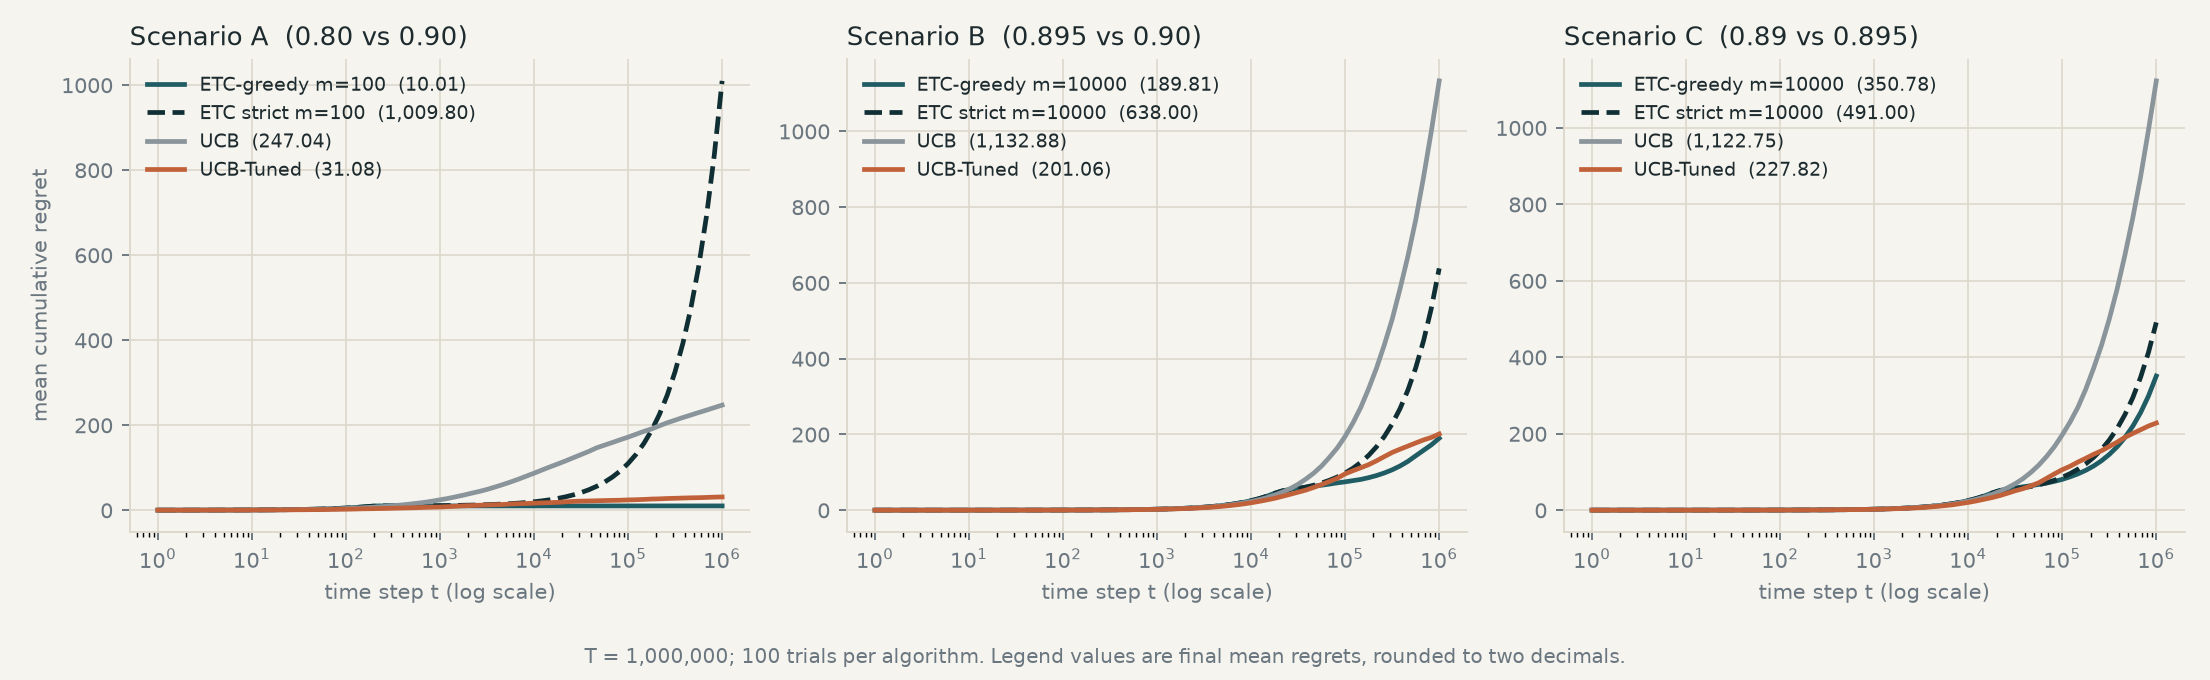

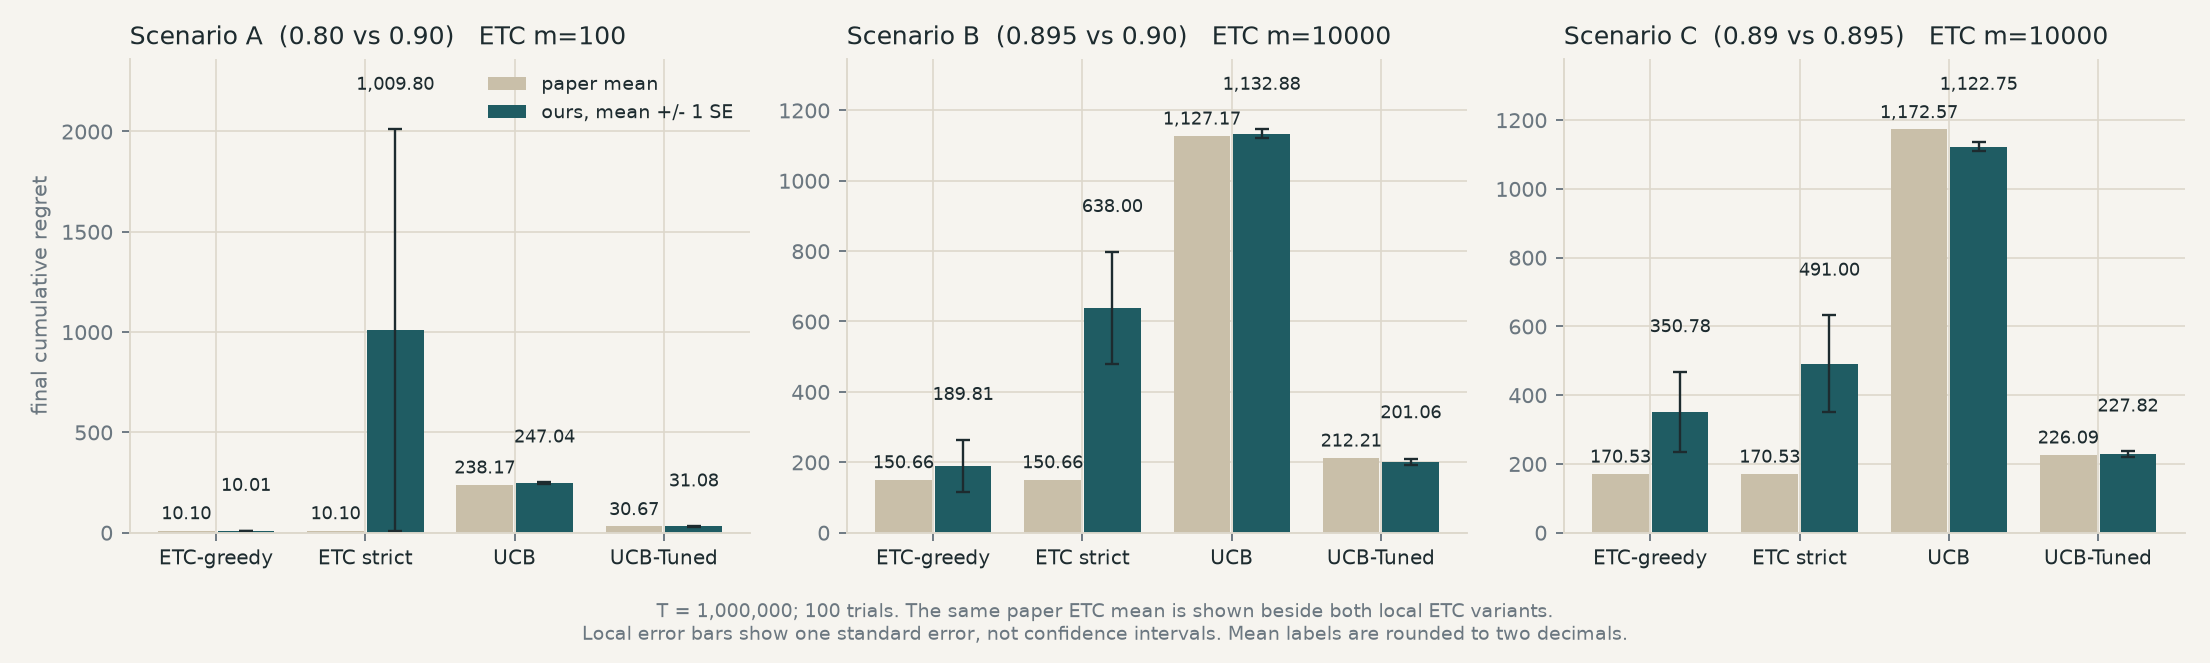

Figures saved in results/; T=1,000,000; trials=100


In [9]:
raw = make_figures(OUT)
display(Image(filename=str(OUT / "regret_curves.png")))
display(Image(filename=str(OUT / "final_regret_vs_paper.png")))
print(f"Figures saved in {OUT.name}/; T={raw['horizon']:,}; trials={raw['trials']:,}")

## 9. Interpretation and references

At the full settings, UCB-Tuned has lower mean regret than UCB in all three scenarios; all six local UCB/UCB-Tuned means are within 6% of the paper. Absolute savings are larger in the micro-gap cases, while the largest relative reduction is in A. ETC performance depends on its exploration budget and whether estimates keep updating; these experiments establish no universal winner.

The paper's ETC text describes fixed commitment, whereas its [pinned ETC implementation, lines 45-57](https://github.com/eelisee/bandit_playground/blob/ab0e657070c41089ed37d9795f297d067bd84903/src/algorithms/ETC.py#L45-L57) reselects an empirical best arm each round. Both local variants are therefore reported. Bernoulli means and variances are coupled; this setup does not isolate variance effects. Randomized arm order, seeds and checkpoints differ from the full framework.

The pinned [analysis notebook](https://github.com/eelisee/bandit_playground/blob/ab0e657070c41089ed37d9795f297d067bd84903/src/experiments-SKILL.ipynb) uses 100 terminal trial totals but 999,999 chi-square degrees of freedom in its variance calculation. The usual independent normal-data variance test would use 99. This concern does not test regret differences; our reproduction does not recompute those p-values.

References: Wolf (2025), arXiv:2510.27001; Auer, Cesa-Bianchi and Fischer (2002), *Finite-time analysis of the multiarmed bandit problem*; Lattimore and Szepesvari (2020), *Bandit Algorithms*.